In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
np.random.seed(42)
random.seed(42)

#hox_genes = sorted([g for g in sub3.var_names if g.startswith(("Hoxa", "Hoxb", "Hoxc", "Hoxd"))]); print(hox_genes)

In [2]:
adata=sc.read_h5ad('/home/julia/data/placodes/h5ad/E9_E10_E11_UMAP.h5ad')

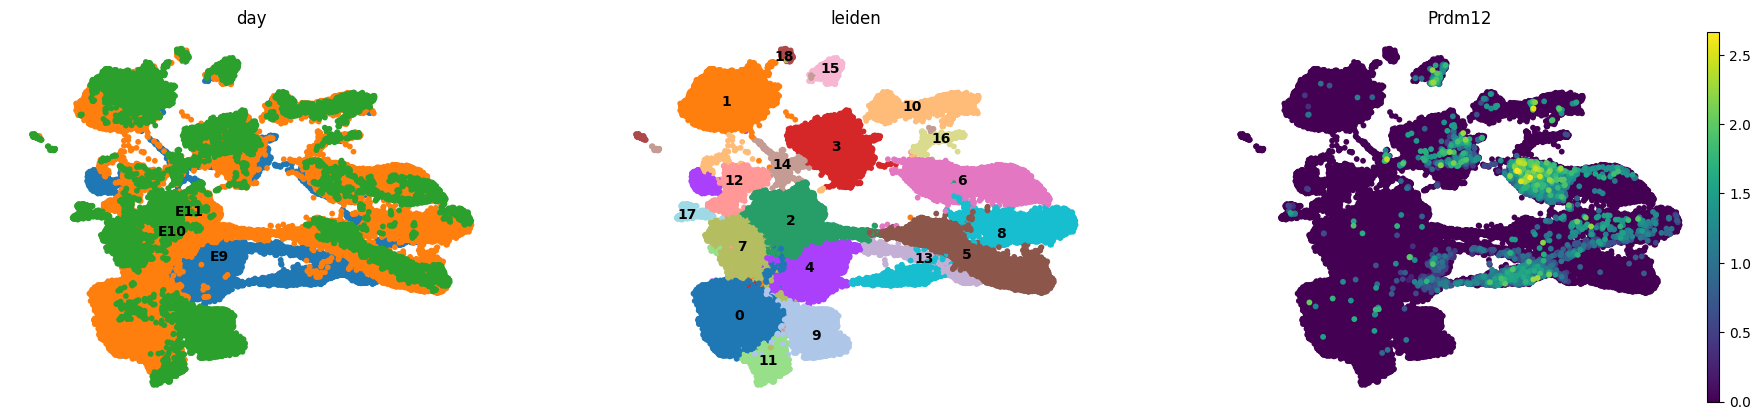

In [3]:
sc.pl.umap(adata, color=["day", "leiden", 'Prdm12'],  frameon=False, size=70, legend_loc='on data')

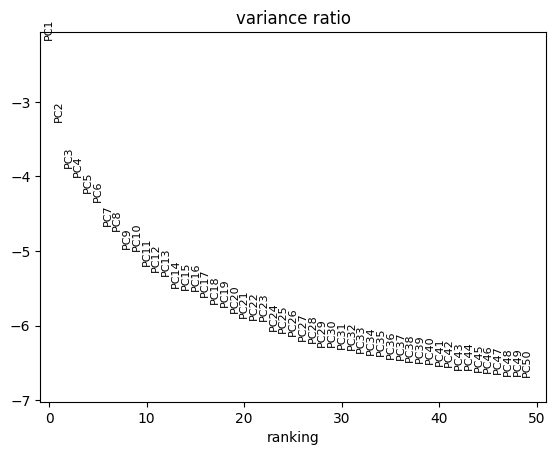

In [4]:
CLUSTERS = ["4", "8", "13"]   # ← ваши кластеры
sub = adata[adata.obs["leiden"].isin(CLUSTERS)].copy()
sub.obs["leiden_parent"] = sub.obs["leiden"].astype(str)
#sc.pp.filter_genes(sub, min_cells=5)

sub.X = sub.layers["counts"].copy()
sc.pp.normalize_total(sub, target_sum=1e4)
sc.pp.log1p(sub)
sub.layers["lognorm"] = sub.X.copy()
sc.pp.highly_variable_genes(sub, flavor="seurat_v3", layer="counts", n_top_genes=2000)

# скейлинг + PCA во временной копии
tmp = sub[:, sub.var["highly_variable"]].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=50)
sc.pl.pca_variance_ratio(tmp, n_pcs=50, log=True)

sub.obsm["X_pca"] = tmp.obsm["X_pca"]
sub.uns["pca"] = tmp.uns["pca"]
del tmp

In [5]:
sc.pp.neighbors(sub, n_pcs=30, n_neighbors=35)   # n_pcs по графику локтя
sc.tl.leiden(sub, resolution=0.4, key_added="leiden_sub4")

/tmp/ipykernel_2572725/1249705935.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(sub, resolution=0.4, key_added="leiden_sub4")


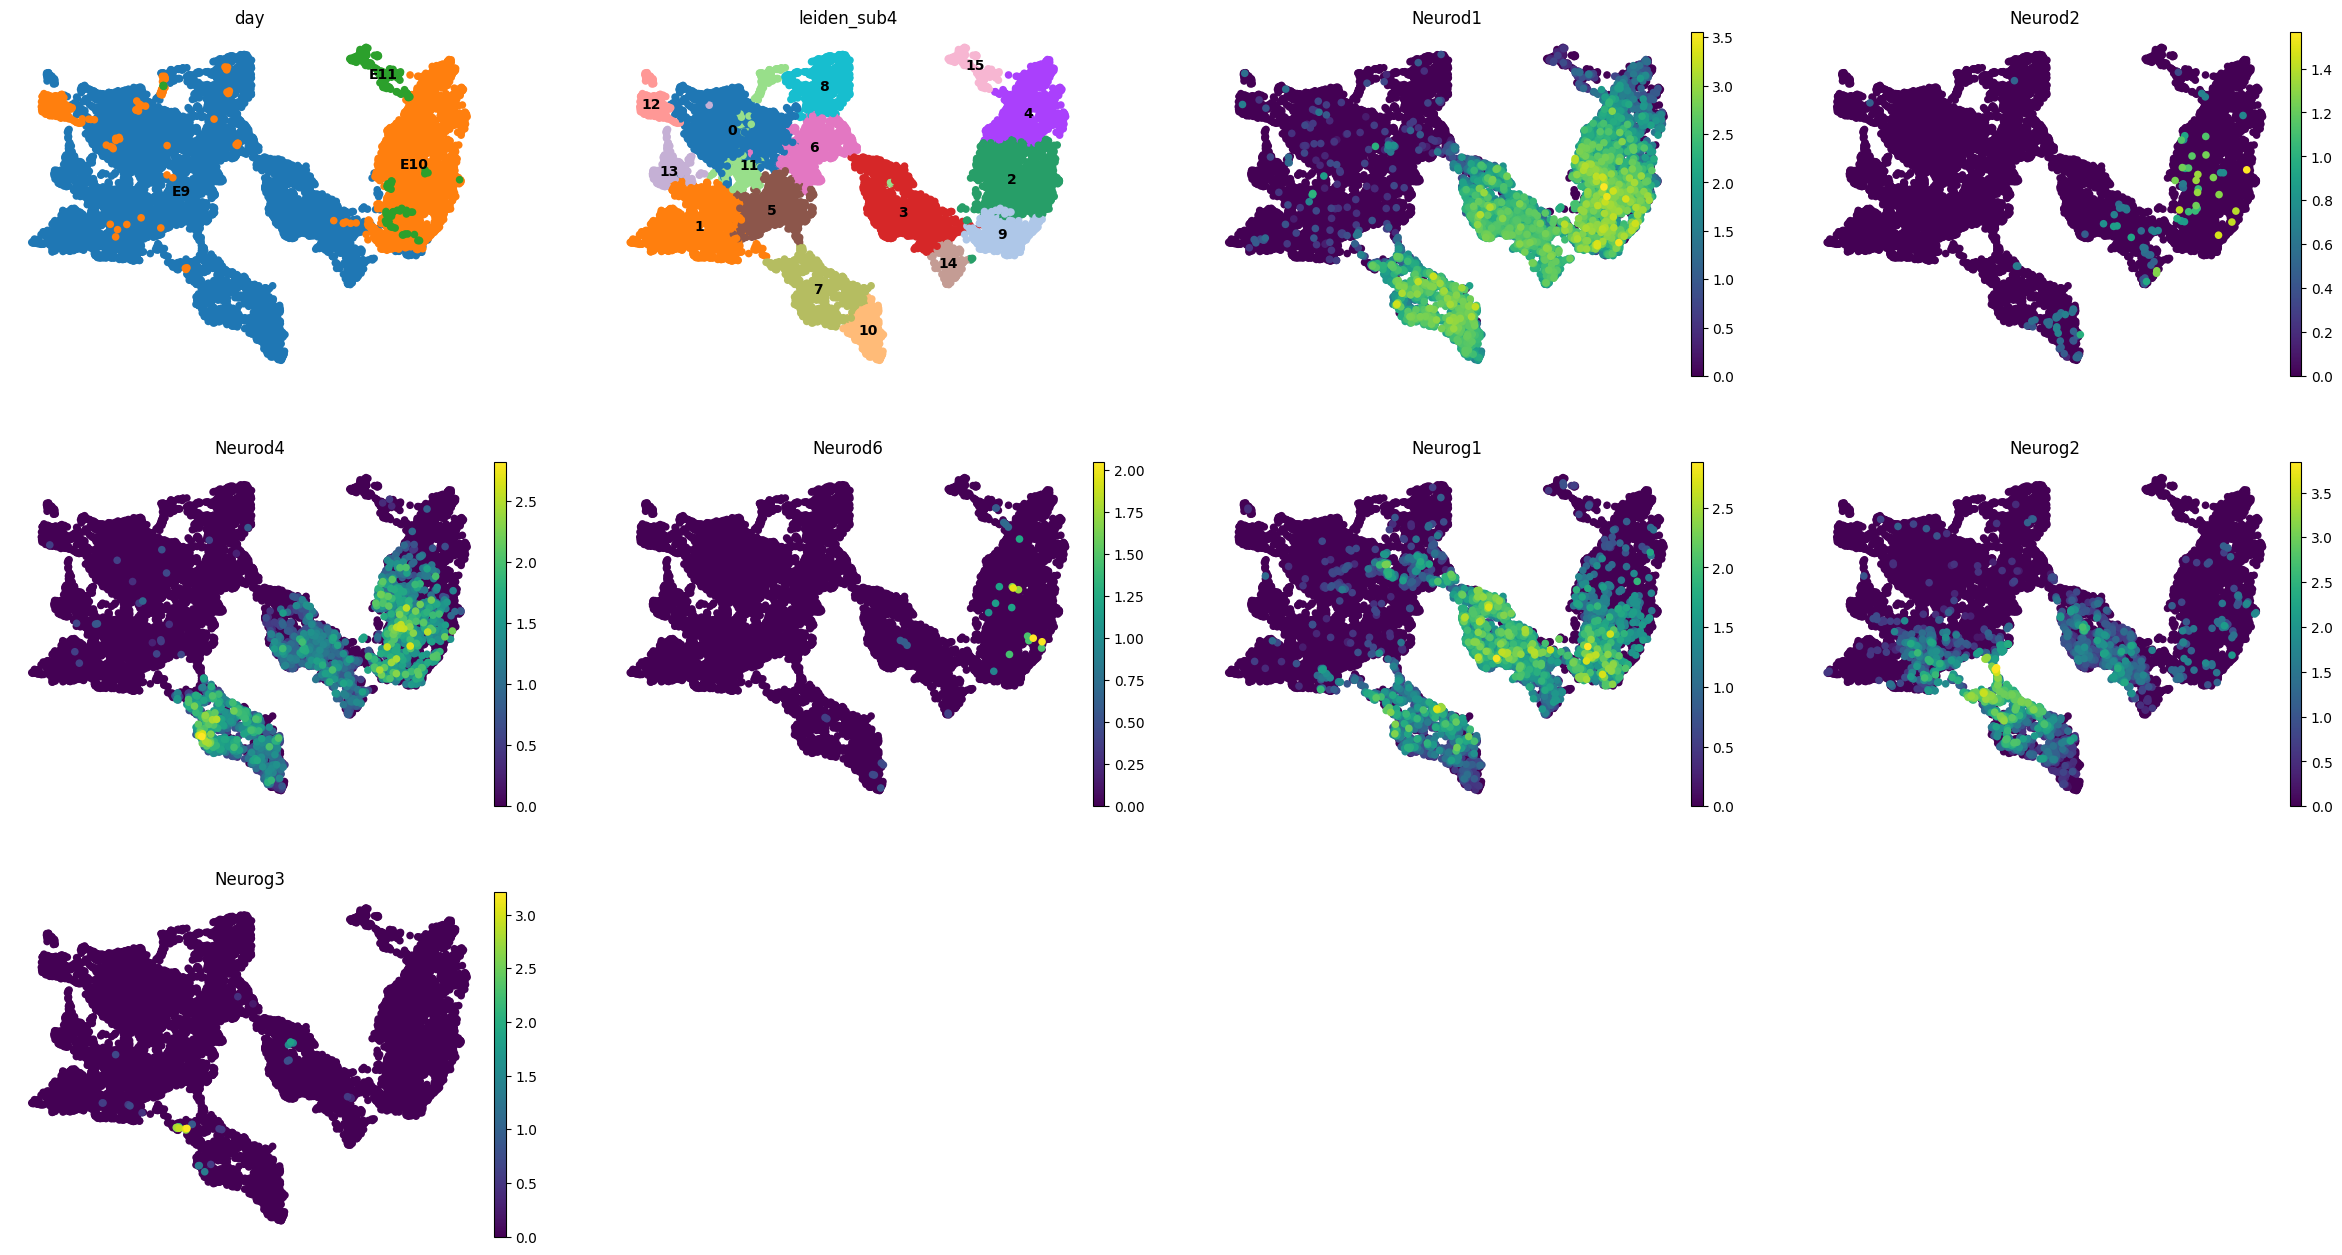

In [6]:
sc.tl.umap(sub)
sc.pl.umap(sub, color=["day", "leiden_sub4",  'Neurod1', 'Neurod2', 'Neurod4', 'Neurod6', 'Neurog1', 'Neurog2', 'Neurog3'], size=120, frameon=False, legend_loc='on data')

In [7]:
sub.write_h5ad('/home/julia/Placodes_subset_2/both_branches.h5ad')

In [6]:
#sub=sc.read_h5ad('/home/julia/Placodes_subset_2/both_branches.h5ad')

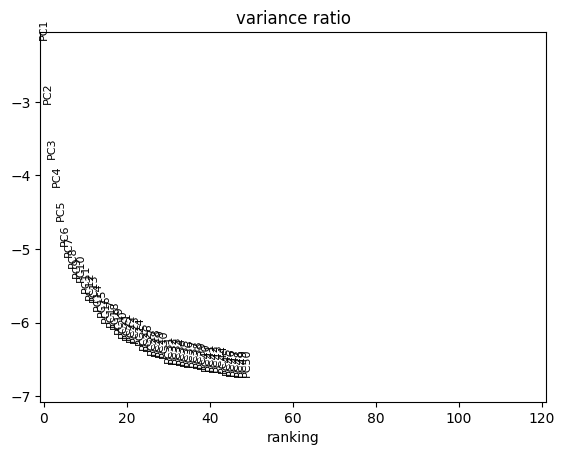

In [8]:
# 1. Subset
sub2 = sub[sub.obs["leiden_sub4"].astype(str).isin(["6", "3", "14", '9', '2', '4', '15'])].copy()
sub2.obs["leiden_parent"] = sub2.obs["leiden_sub4"].astype(str)
sub2.X = sub2.layers["lognorm"].copy()

# 2. HVGs
#sc.pp.filter_genes(sub2, min_cells=5)
sc.pp.highly_variable_genes(sub2, flavor="seurat_v3",
                            layer="counts", n_top_genes=2500)

#bad = sub2.var_names.str.startswith(("mt-", "Rps", "Rpl"))
#sub2.var.loc[bad, "highly_variable"] = False

# 3. PCA
tmp = sub2[:, sub2.var["highly_variable"]].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=50)
sc.pl.pca_variance_ratio(tmp, n_pcs=120, log=True)

sub2.obsm["X_pca"] = tmp.obsm["X_pca"].copy()
del tmp

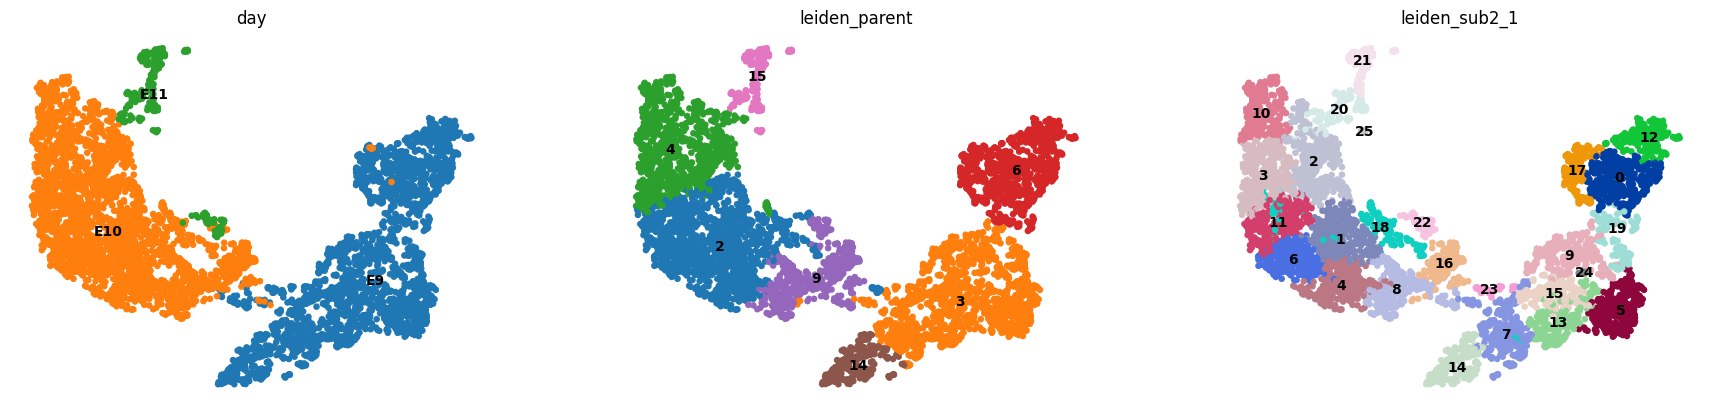

In [9]:
sc.pp.neighbors(sub2, n_neighbors=35, n_pcs=50)
sc.tl.umap(sub2)
sc.tl.leiden(sub2, resolution=1.4, key_added="leiden_sub2_1")

# 5. Plot
sc.pl.umap(sub2, color=["day", "leiden_parent", "leiden_sub2_1"],
           frameon=False, legend_loc="on data", size=90)

In [10]:
sub2.write_h5ad('/home/julia/Placodes_subset_2/Sub_8_13_4_UMAP_06_11.h5ad')

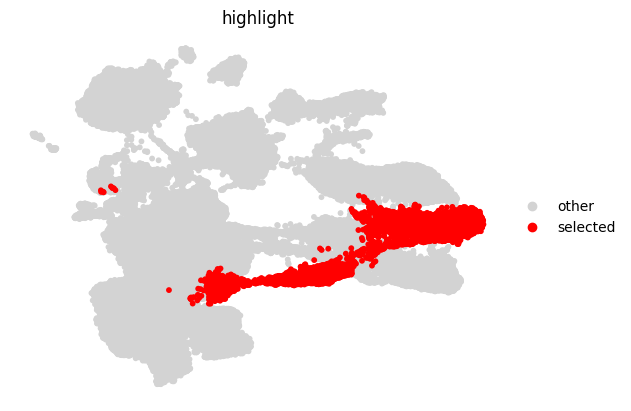

In [11]:
# take cells from your final subset
cells_of_interest = sub2.obs_names   # change sub3 to your final subset object

# create a label in the original adata
adata.obs["highlight"] = "other"
adata.obs.loc[cells_of_interest, "highlight"] = "selected"

# plot selected cells on top
idx_other = np.where(adata.obs["highlight"] == "other")[0]
idx_sel   = np.where(adata.obs["highlight"] == "selected")[0]
idx = np.concatenate([idx_other, idx_sel])

sc.pl.umap(
    adata[idx].copy(),
    color="highlight",
    palette={"other": "lightgrey", "selected": "red"},
    size=70,
    frameon=False,
    legend_loc="right margin", #save='sub_cl.pdf'
)